In [2]:
from pathlib import Path
import scienceplots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report
import pywt
from scipy.stats import skew
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestClassifier
from Gyroscope_data import RawGyroscopeXYZData, RawAccelerometerXYZData
from scipy.signal import periodogram
import xgboost as xgb
import re
plt.style.use('science')
# --- Feature extraction ---
def dominant_freq(signal: np.ndarray, fs: float) -> float:
    f, Pxx = periodogram(signal, fs)
    return f[np.argmax(Pxx)] if len(f) > 0 else 0.0


import pandas as pd
import numpy as np
def iqr(data):
    q75, q25 = np.percentile(data, [75, 25])
    return q75 - q25
def resample_df(df, time_col='time', target_freq=20.0):
    df = df.sort_values(time_col)
    df[time_col] = pd.to_datetime(df[time_col], unit='ms')
    df.set_index(time_col, inplace=True)

    resampled = df.resample(f'{int(1000/target_freq)}ms').mean()
    resampled = resampled.interpolate(method='linear')  # or 'spline', 'time'
    
    resampled.reset_index(inplace=True)
    resampled[time_col] = resampled[time_col].astype(np.int64) // 10**6  # back to ms
    return resampled

def extract_features_from_gyro_df_with_meta(
    df, label, fs=20.0, window_s=2.0, step_s=0.5, time_col=None
):
    """
    Returns:
      X : (n_windows, n_features) numpy array
      y : (n_windows,) numpy array (all 'label' here)
      meta : DataFrame with start/end/center times and sample indices
             columns: ['t_start','t_end','t_center','i_start','i_end','window_len','step_len']
    If time_col is None, t_start/t_end are computed from sample index / fs.
    Otherwise they’re taken from df[time_col] (must be monotonic).
    """
    window_len = int(fs * window_s)
    step_len   = int(fs * step_s)
    n = len(df)

    feats = []
    labels = []
    meta_rows = []

    # If user gave timestamps, normalize to float seconds
    if time_col is not None:
        t_series = pd.to_datetime(df[time_col]) if np.issubdtype(df[time_col].dtype, np.datetime64) else df[time_col]
        if np.issubdtype(t_series.dtype, np.datetime64):
            t_seconds = (t_series.view('int64') / 1e9).to_numpy()
        else:
            t_seconds = pd.Series(t_series, copy=False).astype(float).to_numpy()
    else:
        # start at 0 seconds
        t_seconds = np.arange(n, dtype=float) / float(fs)

    for i_start in range(0, n - window_len + 1, step_len):
        i_end = i_start + window_len
        window = df.iloc[i_start:i_end]

        f = []
        # Accelerometer features
        for axis in ['x_acc', 'y_acc', 'z_acc']:
            data = window[axis].to_numpy()
            f.append(dominant_freq(data, fs=fs))
            f.append(np.sum(data**2))     # energy
            f.append(np.var(data))
            f.append(np.mean(data))
            f.append(np.median(data))
            f.append(iqr(data))
            f.append(np.max(data))
            f.append(np.min(data))


        # Gyroscope features (bugfix: define 'data' for each axis)
        for axis in ['x_gyr', 'y_gyr', 'z_gyr']:
            data = window[axis].to_numpy()
            f.append(dominant_freq(data, fs=fs))
            f.append(np.sum(data**2))     # energy
            f.append(np.var(data))
            f.append(np.mean(data))
            f.append(np.median(data))
            f.append(iqr(data))
            f.append(np.max(data))
            f.append(np.min(data))


        feats.append(f)
        labels.append(label)

        # timing for this window
        t_start  = float(t_seconds[i_start])
        t_end    = float(t_seconds[i_end-1])  # last sample time
        # Make end the *exclusive* bound for voting; add 1 sample step:
        t_end_ex = t_end + (1.0/fs)
        meta_rows.append({
            't_start': t_start,
            't_end':   t_end_ex,  # exclusive end
            't_center': (t_start + t_end_ex) * 0.5,
            'i_start': i_start,
            'i_end':   i_end,
            'window_len': window_len,
            'step_len':   step_len
        })

    X = np.asarray(feats, dtype=float)
    y = np.asarray(labels)
    meta = pd.DataFrame(meta_rows)
    return X, y, meta

# -----------------------------------
# 2) Predict per-window with XGBoost
# -----------------------------------
def predict_windows_df(model, X, meta, class_names=None):
    """
    model: trained classifier with predict and predict_proba
    class_names: list/array of class labels in the same order as model.predict_proba columns.
                 If None, tries model.classes_.
    Returns df_windows with: t_start, t_end, pred, and probability columns 'proba_<class>'
    """
    preds = model.predict(X)
    df = meta[['t_start','t_end']].copy()
    df['pred'] = preds

    if hasattr(model, "predict_proba"):
        P = model.predict_proba(X)
        if class_names is None:
            class_names = getattr(model, "classes_", [str(i) for i in range(P.shape[1])])
        for j, c in enumerate(class_names):
            df[f'proba_{c}'] = P[:, j]
    return df

# -----------------------------------
# 3) Per-second aggregation (voting)
# -----------------------------------
def _to_seconds_series(x):
    s = pd.Series(x)
    if np.issubdtype(s.dtype, np.datetime64):
        return (s.view('int64') / 1e9).astype(float)
    return s.astype(float)

def aggregate_predictions_by_second(
    df_windows: pd.DataFrame,
    *,
    start_col='t_start',
    end_col='t_end',
    pred_col='pred',
    proba_prefix='proba_',
    t0=None,
    t1=None
) -> pd.DataFrame:
    t_start = _to_seconds_series(df_windows[start_col]).to_numpy()
    t_end   = _to_seconds_series(df_windows[end_col]).to_numpy()
    preds   = df_windows[pred_col].to_numpy()

    # find probability columns if present
    proba_cols = [c for c in df_windows.columns if c.startswith(proba_prefix)]
    have_proba = len(proba_cols) > 0
    if have_proba:
        classes = [c[len(proba_prefix):] for c in proba_cols]
        probas  = df_windows[proba_cols].to_numpy(dtype=float)

    if t0 is None: t0 = int(np.floor(t_start.min()))
    if t1 is None: t1 = int(np.ceil(t_end.max()))

    rows = []
    for sec in range(t0, t1):
        bin_start, bin_end = float(sec), float(sec+1)
        mask = (t_start < bin_end) & (t_end > bin_start)
        idx = np.flatnonzero(mask)
        if idx.size == 0:
            rows.append({'sec_start': sec, 'label_hard': None, 'label_soft': None,
                         'confidence_soft': None, 'n_windows': 0})
            continue

        overlap = np.minimum(t_end[idx], bin_end) - np.maximum(t_start[idx], bin_start)
        overlap = np.clip(overlap, 0, 1)

        # Hard vote (overlap-weighted)
        # Sum weights by label
        weights = {}
        for i, w in zip(idx, overlap):
            lab = preds[i]
            weights[lab] = weights.get(lab, 0.0) + float(w)
        label_hard = max(weights.items(), key=lambda kv: kv[1])[0]

        # Soft vote
        if have_proba:
            w = overlap.reshape(-1, 1)
            p = probas[idx]
            wsum = w.sum()
            p_sec = (p * w).sum(axis=0) / (wsum if wsum > 0 else 1.0)
            j = int(np.argmax(p_sec))
            label_soft = classes[j]
            confidence_soft = float(p_sec[j])
        else:
            label_soft, confidence_soft = None, None

        rows.append({
            'sec_start': sec,
            'label_hard': label_hard,
            'label_soft': label_soft,
            'confidence_soft': confidence_soft,
            'n_windows': int(idx.size)
        })
    return pd.DataFrame(rows)

# -----------------------------------
# 4) Convenience: do it all at once
# -----------------------------------
def predict_and_vote_per_second(
    df, model, label_for_training_set, *, fs=20.0, window_s=2.0, step_s=0.5, time_col=None, class_names=None
):
    """
    Runs extraction -> window predictions -> per-second voting.
    Note: label_for_training_set is ignored for predictions (kept for compatibility with your function).
    """
    X, y, meta = extract_features_from_gyro_df_with_meta(
        df, label_for_training_set, fs=fs, window_s=window_s, step_s=step_s, time_col=time_col
    )
    df_windows = predict_windows_df(model, X, meta, class_names=class_names)
    #for i in range(1, len(df_windows)-1, 1):
        #if df_windows['pred'][i-1] == df_windows['pred'][i+1]:
            #df_windows.iloc[i, df_windows.columns.get_loc('pred')] = df_windows['pred'][i-1]
    per_sec = aggregate_predictions_by_second(df_windows)
    return df_windows, per_sec

# --- Data loader ---
def load_data_from_labeled_subfolders(base_path: str,
                                      suffix_gyro='-Gyro.txt',
                                      suffix_accel='-Accel.txt') -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    X_all = []
    y_all = []
    meta_all = []


    base = Path(base_path)
    for subfolder in base.iterdir():
        if not subfolder.is_dir():
            continue

        label = subfolder.name.lower()
        print(f"📂 Processing label: {label}")

        gyro_files = list(subfolder.glob(f"*{suffix_gyro}"))
        pattern = re.compile(r"(.+)-(\d+)" + re.escape(suffix_gyro))  # Matches "prefix-1-Gyro.txt"
        prefixes = []

        for f in gyro_files:
            match = pattern.match(f.name)
            if match:
                base_prefix, i = match.groups()
                prefixes.append((base_prefix, int(i)))

        for base_prefix, i in sorted(set(prefixes)):
            try:
                print(f"🔎 Loading files: {base_prefix}-{i}{suffix_accel} and {base_prefix}-{i}{suffix_gyro}")

                accel = RawAccelerometerXYZData(folder=subfolder, date=base_prefix, suffix=suffix_accel, i=[i], save_as_csv=False)
                gyro  = RawGyroscopeXYZData(folder=subfolder, date=base_prefix, suffix=suffix_gyro, i=[i], save_as_csv=False)
        
                gyro.compute_orientation(other=accel)
                gyro.df = resample_df(gyro.df, target_freq=20.0)

                print(f"🔍 Extracting features for {label}/{base_prefix}-{i}...")
                X, y, meta = extract_features_from_gyro_df_with_meta(gyro.df, label=label, fs = 20.0, window_s=2.0, step_s=0.5, time_col='time')
                X_all.append(X)
                y_all.append(y)
                meta_all.append(meta)

            except Exception as e:
                print(f"⚠️ Skipped {label}/{base_prefix}-{i} due to error: {e}")

    if not X_all:
        raise RuntimeError("No valid data was loaded. Check folder structure and filenames.")

    return np.vstack(X_all), np.concatenate(y_all), pd.concat(meta_all)

# --- Run everything ---

In [3]:
base_dir = "C:/Watch_data/data_store"  # Update this if needed

X, y, meta = load_data_from_labeled_subfolders(base_dir)

print(f"\n✅ Loaded {len(X)} windows from {np.unique(y).size} classes.")
for lbl in np.unique(y):
    print(f"  - {lbl}: {(y == lbl).sum()} windows")

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Train decision tree


def plot_feature_importance(model, feature_names=None):
    importances = model.feature_importances_
    idxs = np.argsort(importances)[::-1]
    plt.figure(figsize=(10, 5))
    plt.bar(range(len(importances)), importances[idxs])
    if feature_names:
        plt.xticks(range(len(importances)), [feature_names[i] for i in idxs], rotation=45, ha='right')
    plt.title("Feature Importances (Random Forest)")
    plt.tight_layout()
    plt.show()


feature_names = ['x_acc_freq', 'x_acc_energy', 'x_acc_var', 'x_acc_mean', 'x_acc_median', 'x_acc_iqr', 'x_acc_max', 'x_acc_min'
                 'y_acc_freq', 'y_acc_energy', 'y_acc_var', 'y_acc_mean', 'y_acc_median', 'y_acc_iqr', 'y_acc_max', 'y_acc_min'
                 'z_acc_freq', 'z_acc_energy', 'z_acc_var', 'z_acc_mean', 'z_acc_median', 'z_acc_iqr', 'z_acc_max', 'z_acc_min'
                 'x_gyr_freq', 'x_gyr_energy', 'x_gyr_var', 'x_gyr_mean', 'x_gyr_median', 'x_gyr_iqr', 'x_gyr_max', 'x_gyr_min'
                 'y_gyr_freq', 'y_gyr_energy', 'y_gyr_var', 'y_gyr_mean', 'y_gyr_median', 'y_gyr_iqr', 'y_gyr_max', 'y_gyr_min'
                 'z_gyr_freq', 'z_gyr_energy', 'z_gyr_var', 'z_gyr_mean', 'z_gyr_median', 'z_gyr_iqr', 'z_gyr_max', 'z_gyr_min']
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Converts strings to integers

# Now split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, stratify=y_encoded, random_state=1)




# Create model
xgb_model = XGBClassifier(
    objective='multi:softprob',
    eval_metric='mlogloss',
    num_class=len(np.unique(y)),
    random_state=42,
    colsample_bytree=0.8,
    subsample=0.8,
    max_depth=5,
    gamma=0,
    min_child_weight=1,
    learning_rate=0.2,
    n_estimators=100

)

xgb_model.fit(X_train, y_train)


# Evaluate
y_pred = xgb_model.predict(X_test)
y_pred_labels = le.inverse_transform(y_pred)
y_test_labels = le.inverse_transform(y_test)
print("\n🧠 Classification Report (Best XGBoost):")
print(classification_report(y_test_labels, y_pred_labels))

📂 Processing label: household
🔎 Loading files: 2025-08-10-12-05-1-Accel.txt and 2025-08-10-12-05-1-Gyro.txt
Orientation computed using Madgwick filter over 3066 samples
🔍 Extracting features for household/2025-08-10-12-05-1...
🔎 Loading files: 2025-08-10-12-05-2-Accel.txt and 2025-08-10-12-05-2-Gyro.txt
Orientation computed using Madgwick filter over 818 samples
🔍 Extracting features for household/2025-08-10-12-05-2...
🔎 Loading files: 2025-08-10-14-14-1-Accel.txt and 2025-08-10-14-14-1-Gyro.txt
Orientation computed using Madgwick filter over 3062 samples
🔍 Extracting features for household/2025-08-10-14-14-1...
🔎 Loading files: 2025-08-10-14-14-2-Accel.txt and 2025-08-10-14-14-2-Gyro.txt
Orientation computed using Madgwick filter over 3058 samples
🔍 Extracting features for household/2025-08-10-14-14-2...
🔎 Loading files: 2025-08-10-14-14-3-Accel.txt and 2025-08-10-14-14-3-Gyro.txt
Orientation computed using Madgwick filter over 3060 samples
🔍 Extracting features for household/2025-08-

In [4]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict on test set
y_pred = xgb_model.predict(X_test)

# If you used LabelEncoder:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(y)  # Assuming 'y' contains all the labels

# Compute confusion matrix
cm = confusion_matrix(le.inverse_transform(y_test), le.inverse_transform(y_pred), labels=le.classes_)

# Plot it
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()
#new_base_path = "C:/Watch_data/Jeff_test"

RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 800x600 with 2 Axes>

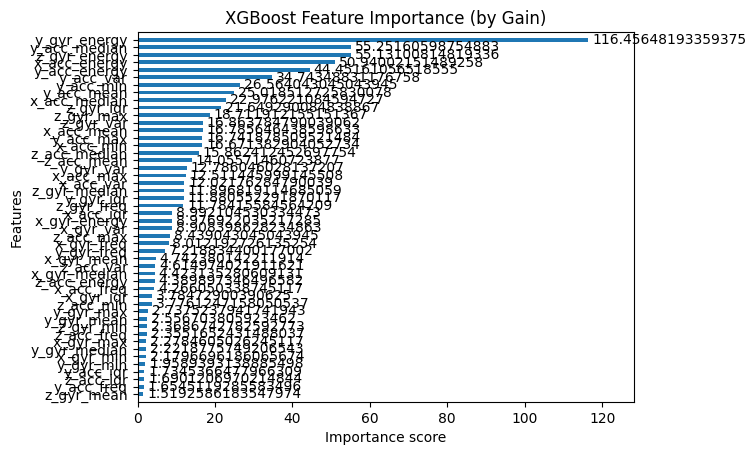

In [ ]:
#X_new, y_new = load_data_from_labeled_subfolders(new_base_path)
feature_names = ['x_acc_freq', 'x_acc_energy', 'x_acc_var', 'x_acc_mean', 'x_acc_median', 'x_acc_iqr', 'x_acc_max', 'x_acc_min',
                 'y_acc_freq', 'y_acc_energy', 'y_acc_var', 'y_acc_mean', 'y_acc_median', 'y_acc_iqr', 'y_acc_max', 'y_acc_min',
                 'z_acc_freq', 'z_acc_energy', 'z_acc_var', 'z_acc_mean', 'z_acc_median', 'z_acc_iqr', 'z_acc_max', 'z_acc_min',
                 'x_gyr_freq', 'x_gyr_energy', 'x_gyr_var', 'x_gyr_mean', 'x_gyr_median', 'x_gyr_iqr', 'x_gyr_max', 'x_gyr_min',
                 'y_gyr_freq', 'y_gyr_energy', 'y_gyr_var', 'y_gyr_mean', 'y_gyr_median', 'y_gyr_iqr', 'y_gyr_max', 'y_gyr_min',
                 'z_gyr_freq', 'z_gyr_energy', 'z_gyr_var', 'z_gyr_mean', 'z_gyr_median', 'z_gyr_iqr', 'z_gyr_max', 'z_gyr_min']
booster = xgb_model.get_booster()
booster.feature_names = feature_names
xgb.plot_importance(booster, importance_type='gain', max_num_features=60, height=0.5)
plt.title("XGBoost Feature Importance (by Gain)")
plt.grid(False)
plt.show()
#y_pred_new = xgb_model.predict(X_new)
#from sklearn.metrics import classification_report, confusion_matrix
#y_pred_labels = le.inverse_transform(y_pred_new)
#print(classification_report(y_new, y_pred_labels))

Orientation computed using Madgwick filter over 430 samples
🔍 Extracting features for test data...


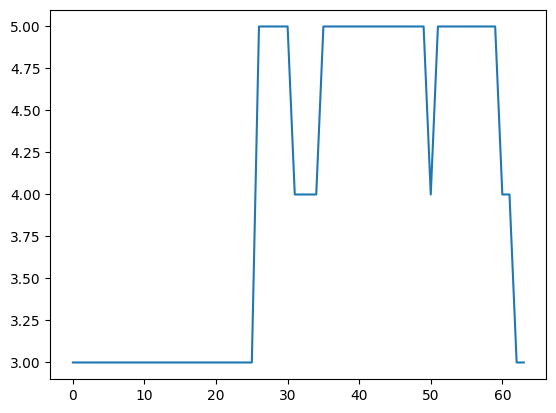

In [ ]:
test_dir = 'C:/Watch_data/test_2'
accel_test = RawAccelerometerXYZData(folder=test_dir, date='2025-08-11-11-18', suffix='-Accel.txt', i=[1], save_as_csv=False)
gyro_test = RawGyroscopeXYZData(folder=test_dir, date='2025-08-11-11-18', suffix='-Gyro.txt', i=[1], save_as_csv=False)
gyro_test.compute_orientation(other=accel_test)
gyro_test.df = resample_df(gyro_test.df, target_freq=20.0)

print(f"🔍 Extracting features for test data...")
X_test_new, y_test_new, meta = extract_features_from_gyro_df_with_meta(gyro_test.df, label='test')
y_new_pred = xgb_model.predict(X_test_new)
y_new_pred_labels = le.inverse_transform(y_new_pred)
plt.plot(y_new_pred)
plt.show()

In [ ]:
df_windows, per_sec = predict_and_vote_per_second(
    df=gyro_test.df,
    model=xgb_model,
    label_for_training_set='(unused here)',
    fs=20.0,
    window_s=2.0,
    step_s=0.5,
    time_col='time',        # or None to assume t=0 + i/fs
    class_names=None             # or list(model.classes_) if needed
)
df_windows['time_center'] = df_windows['t_start'] + 0.5  # Center time for plotting
df_windows['time'] = pd.to_datetime(df_windows['time_center'], unit='ms')


        t_start         t_end  pred   proba_0   proba_1   proba_2   proba_3  \
0  1.754911e+12  1.754911e+12     3  0.161705  0.000925  0.000725  0.335832   
1  1.754911e+12  1.754911e+12     3  0.008969  0.000596  0.008065  0.753088   
2  1.754911e+12  1.754911e+12     3  0.000047  0.000008  0.000021  0.999616   
3  1.754911e+12  1.754911e+12     3  0.000265  0.000022  0.000802  0.997318   
4  1.754911e+12  1.754911e+12     3  0.000074  0.000008  0.000036  0.996843   

    proba_4   proba_5   proba_6   proba_7   time_center  \
0  0.205693  0.293661  0.000936  0.000523  1.754911e+12   
1  0.092119  0.135831  0.000971  0.000362  1.754911e+12   
2  0.000264  0.000040  0.000002  0.000002  1.754911e+12   
3  0.001428  0.000147  0.000011  0.000007  1.754911e+12   
4  0.002999  0.000036  0.000004  0.000002  1.754911e+12   

                        time  
0 2025-08-11 11:18:00.000500  
1 2025-08-11 11:18:00.500500  
2 2025-08-11 11:18:01.000500  
3 2025-08-11 11:18:01.500500  
4 2025-08-11 11

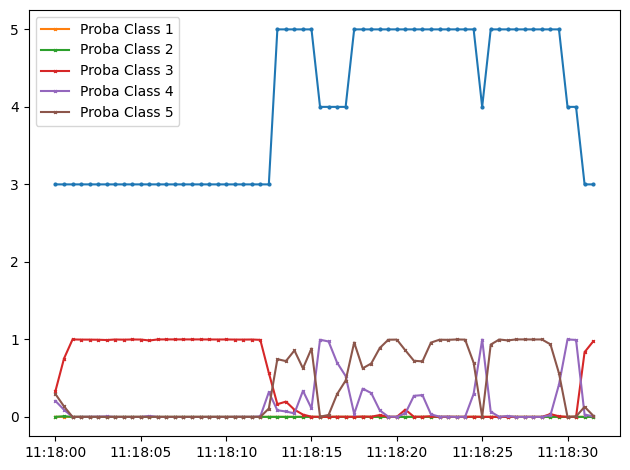

In [ ]:
print(df_windows.head())
plt.plot(df_windows['time'], df_windows['pred'], marker='o', linestyle='-', markersize=2)
plt.plot(df_windows['time'], df_windows['proba_1'], marker='x', linestyle='-', markersize=2, label='Proba Class 1')
plt.plot(df_windows['time'], df_windows['proba_2'], marker='x', linestyle='-', markersize=2, label='Proba Class 2')
plt.plot(df_windows['time'], df_windows['proba_3'], marker='x', linestyle='-', markersize=2, label='Proba Class 3')
plt.plot(df_windows['time'], df_windows['proba_4'], marker='x', linestyle='-', markersize=2, label='Proba Class 4')
plt.plot(df_windows['time'], df_windows['proba_5'], marker='x', linestyle='-', markersize=2, label='Proba Class 5')
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
test_dir = 'C:/Watch_data/test_3'
accel_test = RawAccelerometerXYZData(folder=test_dir, date='2025-08-12-11-09', suffix='-Accel.txt', i=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], save_as_csv=False)
gyro_test = RawGyroscopeXYZData(folder=test_dir, date='2025-08-12-11-09', suffix='-Gyro.txt', i=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], save_as_csv=False)
gyro_test.compute_orientation(other=accel_test)
gyro_test.df = resample_df(gyro_test.df, target_freq=20.0)


Orientation computed using Madgwick filter over 32376 samples


In [ ]:

df_windows_2, per_sec = predict_and_vote_per_second(
    df=gyro_test.df,
    model=xgb_model,
    label_for_training_set='(unused here)',
    fs=20.0,
    window_s=2.0,
    step_s=0.5,
    time_col='time',        # or None to assume t=0 + i/fs
    class_names=None             # or list(model.classes_) if needed

)
print('loaded')
df_windows_2['time_center'] = df_windows_2['t_start'] + 0.5  # Center time for plotting
df_windows_2['time'] = pd.to_datetime(df_windows_2['time_center'], unit='ms')


KeyboardInterrupt: 

0.9747882607839276


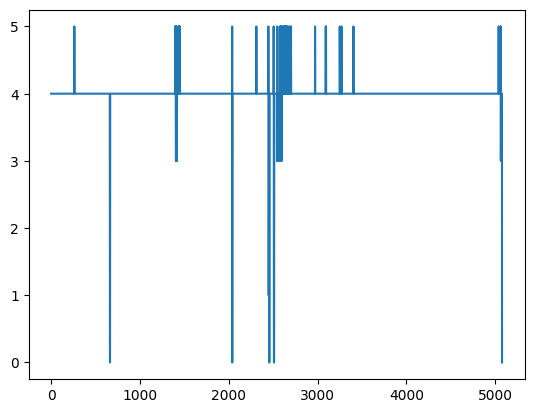

In [ ]:
X_test_new, y_test_new, meta = extract_features_from_gyro_df_with_meta(gyro_test.df, label='test')
y_new_pred = xgb_model.predict(X_test_new)
unique, counts = np.unique(y_new_pred, return_counts=True)

accuracy = counts[3]/sum(counts)
print(accuracy)
y_new_pred_labels = le.inverse_transform(y_new_pred)
plt.plot(y_new_pred)
plt.show()

        t_start         t_end  pred   proba_0   proba_1   proba_2   proba_3  \
0  1.754997e+12  1.754997e+12     4  0.104486  0.003028  0.001147  0.061887   
1  1.754997e+12  1.754997e+12     4  0.004205  0.000201  0.000369  0.014450   
2  1.754997e+12  1.754997e+12     4  0.000096  0.000011  0.000014  0.000083   
3  1.754997e+12  1.754997e+12     4  0.000048  0.000006  0.000005  0.000022   
4  1.754997e+12  1.754997e+12     4  0.000027  0.000022  0.000003  0.000006   

    proba_4   proba_5   proba_6   proba_7   time_center  \
0  0.796416  0.032189  0.000559  0.000290  1.754997e+12   
1  0.890151  0.090375  0.000170  0.000078  1.754997e+12   
2  0.998948  0.000837  0.000005  0.000006  1.754997e+12   
3  0.999851  0.000054  0.000011  0.000002  1.754997e+12   
4  0.999574  0.000361  0.000004  0.000002  1.754997e+12   

                        time  
0 2025-08-12 11:09:00.000500  
1 2025-08-12 11:09:00.500500  
2 2025-08-12 11:09:01.000500  
3 2025-08-12 11:09:01.500500  
4 2025-08-12 11

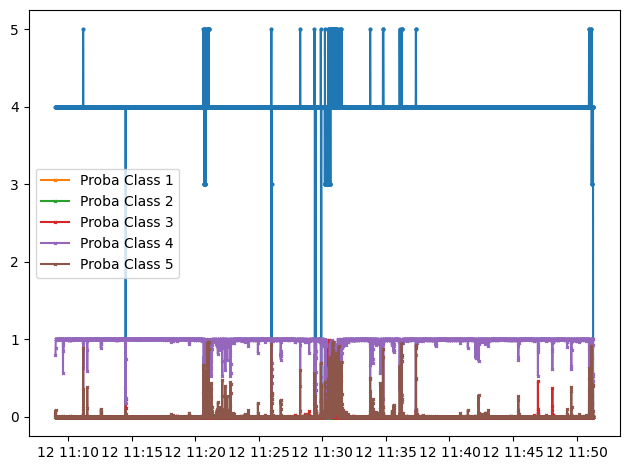

In [ ]:
print(df_windows_2.head())
plt.plot(df_windows_2['time'], df_windows_2['pred'], marker='o', linestyle='-', markersize=2)
plt.plot(df_windows_2['time'], df_windows_2['proba_1'], marker='x', linestyle='-', markersize=2, label='Proba Class 1')
plt.plot(df_windows_2['time'], df_windows_2['proba_2'], marker='x', linestyle='-', markersize=2, label='Proba Class 2')
plt.plot(df_windows_2['time'], df_windows_2['proba_3'], marker='x', linestyle='-', markersize=2, label='Proba Class 3')
plt.plot(df_windows_2['time'], df_windows_2['proba_4'], marker='x', linestyle='-', markersize=2, label='Proba Class 4')
plt.plot(df_windows_2['time'], df_windows_2['proba_5'], marker='x', linestyle='-', markersize=2, label='Proba Class 5')
plt.tight_layout()
plt.legend()
plt.show()

In [5]:
test_dir = 'C:/Watch_data/test_4'
accel_test = RawAccelerometerXYZData(folder=test_dir, date='2025-08-12-12-45', suffix='-Accel.txt', i=[1], save_as_csv=False)
gyro_test = RawGyroscopeXYZData(folder=test_dir, date='2025-08-12-12-45', suffix='-Gyro.txt', i=[1], save_as_csv=False)
gyro_test.compute_orientation(other=accel_test)
gyro_test.df = resample_df(gyro_test.df, target_freq=20.0)

df_windows_4, per_sec = predict_and_vote_per_second(
    df=gyro_test.df,
    model=xgb_model,
    label_for_training_set='(unused here)',
    fs=20.0,
    window_s=2.0,
    step_s=0.5,
    time_col='time',        # or None to assume t=0 + i/fs
    class_names=None             # or list(model.classes_) if needed

)
print('loaded')
df_windows_4['time_center'] = df_windows_4['t_start'] + 0.5  # Center time for plotting
df_windows_4['time'] = pd.to_datetime(df_windows_4['time_center'], unit='ms')

plt.plot(df_windows_4['time'], df_windows_4['pred'], marker='o', linestyle='-', markersize=2)
plt.plot(df_windows_4['time'], df_windows_4['proba_1'], marker='x', linestyle='-', markersize=2, label='Proba Class 1')
plt.plot(df_windows_4['time'], df_windows_4['proba_2'], marker='x', linestyle='-', markersize=2, label='Proba Class 2')
plt.plot(df_windows_4['time'], df_windows_4['proba_3'], marker='x', linestyle='-', markersize=2, label='Proba Class 3')
plt.plot(df_windows_4['time'], df_windows_4['proba_4'], marker='x', linestyle='-', markersize=2, label='Proba Class 4')
plt.plot(df_windows_4['time'], df_windows_4['proba_5'], marker='x', linestyle='-', markersize=2, label='Proba Class 5')
plt.tight_layout()
plt.legend()
plt.show()

Orientation computed using Madgwick filter over 428 samples
loaded


RuntimeError: Failed to process string with tex because latex could not be found

Error in callback <function _draw_all_if_interactive at 0x00000166DA949D00> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 350x262.5 with 1 Axes>

Orientation computed using Madgwick filter over 829 samples
loaded


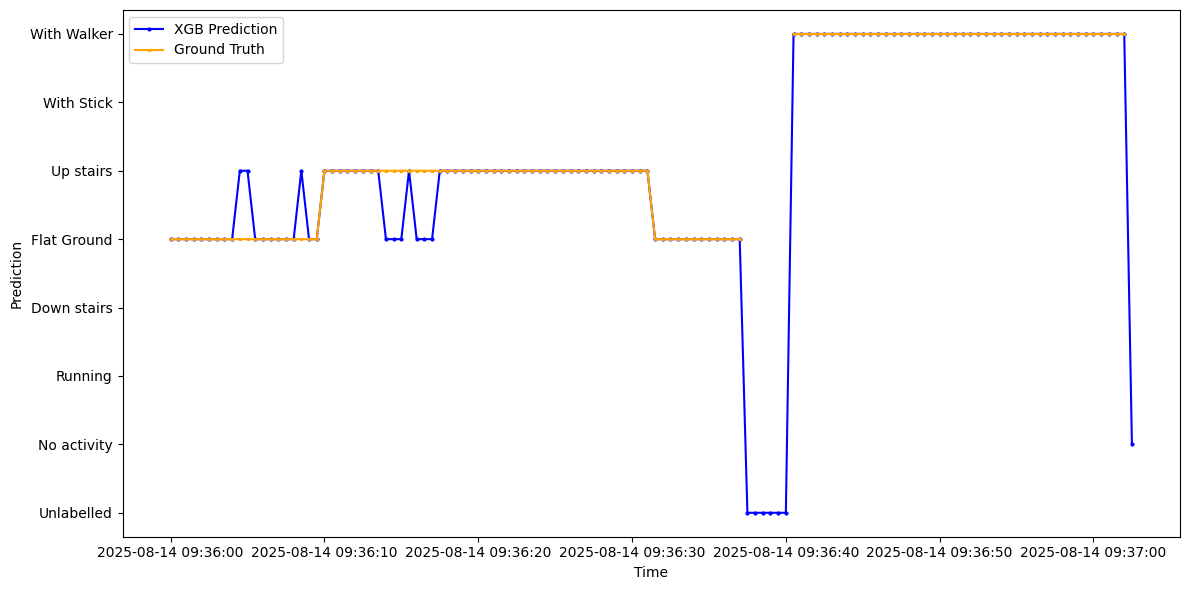

In [ ]:
test_dir = 'C:/Watch_data/test_5'
accel_test = RawAccelerometerXYZData(folder=test_dir, date='2025-08-14-09-36', suffix='-Accel.txt', i=[1], save_as_csv=False)
gyro_test = RawGyroscopeXYZData(folder=test_dir, date='2025-08-14-09-36', suffix='-Gyro.txt', i=[1], save_as_csv=False)
gyro_test.compute_orientation(other=accel_test)
gyro_test.df = resample_df(gyro_test.df, target_freq=20.0)

df_windows_5, per_sec = predict_and_vote_per_second(
    df=gyro_test.df,
    model=xgb_model,
    label_for_training_set='(unused here)',
    fs=20.0,
    window_s=2.0,
    step_s=0.5,
    time_col='time',        # or None to assume t=0 + i/fs
    class_names=None             # or list(model.classes_) if needed

)
df_windows_5['Ground truth'] = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 'NaN', 'NaN', 'NaN', 'NaN', 'NaN', 'NaN', 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7 ,7, 7, 7, 7, 7, 7, 7, 7 ,7 ,7 ,7 ,7 ,7 ,7, 7, 7, 7, 7, 7, 7, 7, 7 ,7 ,7 ,'NaN' ]

ticks = [0,1,2,3,4,5,6,7]
tick_labels = ['Unlabelled', 'No activity', 'Running', 'Down stairs', 'Flat Ground', 'Up stairs', 'With Stick', 'With Walker']
print('loaded')


df_windows_5['time_center'] = df_windows_5['t_start'] + 0.5  # Center time for plotting
df_windows_5['time'] = pd.to_datetime(df_windows_5['time_center'], unit='ms')
fig, ax = plt.subplots(figsize=(12, 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
ax.plot(df_windows_5['time'], df_windows_5['pred'], marker='o', linestyle='-', markersize=2, label = 'XGB Prediction', color = 'blue')
ax.plot(df_windows_5['time'], df_windows_5['Ground truth'], marker='x', linestyle='-', markersize=2, label='Ground Truth', color='orange')
ax.set_xlabel('Time')
ax.set_ylabel('Prediction')
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
df_windows_5['Ground truth'] = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 0, 0, 0, 0, 0, 0, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7 ,7, 7, 7, 7, 7, 7, 7, 7 ,7 ,7 ,7 ,7 ,7 ,7, 7, 7, 7, 7, 7, 7, 7, 7 ,7 ,7 ,7 ,7 ,7 ]

Orientation computed using Madgwick filter over 13258 samples
loaded


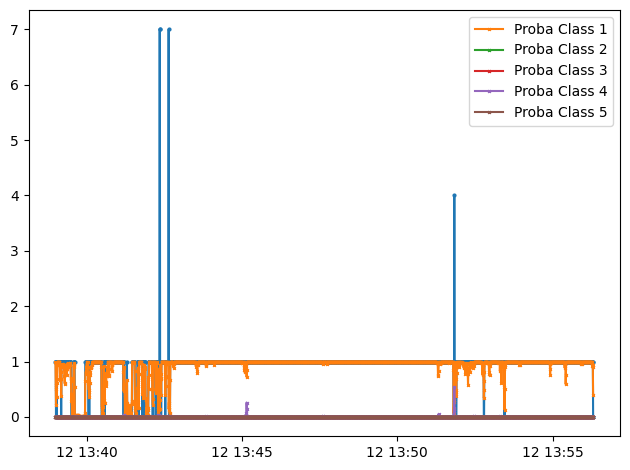

In [ ]:
test_dir = 'C:/Watch_data/test_6'
accel_test = RawAccelerometerXYZData(folder=test_dir, date='2025-08-12-13-39', suffix='-Accel.txt', i=[1, 2, 3, 4, 5], save_as_csv=False)
gyro_test = RawGyroscopeXYZData(folder=test_dir, date='2025-08-12-13-39', suffix='-Gyro.txt', i=[1, 2, 3, 4, 5], save_as_csv=False)
gyro_test.compute_orientation(other=accel_test)
gyro_test.df = resample_df(gyro_test.df, target_freq=20.0)

df_windows_5, per_sec = predict_and_vote_per_second(
    df=gyro_test.df,
    model=xgb_model,
    label_for_training_set='(unused here)',
    fs=20.0,
    window_s=2.0,
    step_s=0.5,
    time_col='time',        # or None to assume t=0 + i/fs
    class_names=None             # or list(model.classes_) if needed

)
print('loaded')
df_windows_5['time_center'] = df_windows_5['t_start'] + 0.5  # Center time for plotting
df_windows_5['time'] = pd.to_datetime(df_windows_5['time_center'], unit='ms')

plt.plot(df_windows_5['time'], df_windows_5['pred'], marker='o', linestyle='-', markersize=2)
plt.plot(df_windows_5['time'], df_windows_5['proba_1'], marker='x', linestyle='-', markersize=2, label='Proba Class 1')
plt.plot(df_windows_5['time'], df_windows_5['proba_2'], marker='x', linestyle='-', markersize=2, label='Proba Class 2')
plt.plot(df_windows_5['time'], df_windows_5['proba_3'], marker='x', linestyle='-', markersize=2, label='Proba Class 3')
plt.plot(df_windows_5['time'], df_windows_5['proba_4'], marker='x', linestyle='-', markersize=2, label='Proba Class 4')
plt.plot(df_windows_5['time'], df_windows_5['proba_5'], marker='x', linestyle='-', markersize=2, label='Proba Class 5')
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
X_test_new, y_test_new, meta = extract_features_from_gyro_df_with_meta(gyro_test.df, label='test')
y_new_pred = xgb_model.predict(X_test_new)
unique, counts = np.unique(y_new_pred, return_counts=True)

accuracy = counts[1]/sum(counts)
print(accuracy)

0.9287433798748195


In [ ]:
base_dir = "C:/Watch_data/Training_on_JE"  # Update this if needed

X, y, meta = load_data_from_labeled_subfolders(base_dir)

print(f"\n✅ Loaded {len(X)} windows from {np.unique(y).size} classes.")
for lbl in np.unique(y):
    print(f"  - {lbl}: {(y == lbl).sum()} windows")

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Train decision tree


def plot_feature_importance(model, feature_names=None):
    importances = model.feature_importances_
    idxs = np.argsort(importances)[::-1]
    plt.figure(figsize=(10, 5))
    plt.bar(range(len(importances)), importances[idxs])
    if feature_names:
        plt.xticks(range(len(importances)), [feature_names[i] for i in idxs], rotation=45, ha='right')
    plt.title("Feature Importances (Random Forest)")
    plt.tight_layout()
    plt.show()


feature_names = ['x_acc_freq', 'x_acc_energy', 'x_acc_var', 'x_acc_mean', 'x_acc_median', 'x_acc_iqr', 'x_acc_max', 'x_acc_min'
                 'y_acc_freq', 'y_acc_energy', 'y_acc_var', 'y_acc_mean', 'y_acc_median', 'y_acc_iqr', 'y_acc_max', 'y_acc_min'
                 'z_acc_freq', 'z_acc_energy', 'z_acc_var', 'z_acc_mean', 'z_acc_median', 'z_acc_iqr', 'z_acc_max', 'z_acc_min'
                 'x_gyr_freq', 'x_gyr_energy', 'x_gyr_var', 'x_gyr_mean', 'x_gyr_median', 'x_gyr_iqr', 'x_gyr_max', 'x_gyr_min'
                 'y_gyr_freq', 'y_gyr_energy', 'y_gyr_var', 'y_gyr_mean', 'y_gyr_median', 'y_gyr_iqr', 'y_gyr_max', 'y_gyr_min'
                 'z_gyr_freq', 'z_gyr_energy', 'z_gyr_var', 'z_gyr_mean', 'z_gyr_median', 'z_gyr_iqr', 'z_gyr_max', 'z_gyr_min']
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Converts strings to integers

# Now split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, stratify=y_encoded, random_state=42)




# Create model
xgb_model = XGBClassifier(
    objective='multi:softprob',
    eval_metric='mlogloss',
    num_class=len(np.unique(y)),
    random_state=42,
    colsample_bytree=0.8,
    subsample=0.8,
    max_depth=5,
    gamma=0,
    min_child_weight=1,
    learning_rate=0.2,
    n_estimators=100

)

xgb_model.fit(X_train, y_train)


# Evaluate
y_pred = xgb_model.predict(X_test)
y_pred_labels = le.inverse_transform(y_pred)
y_test_labels = le.inverse_transform(y_test)
print("\n🧠 Classification Report (Best XGBoost):")
print(classification_report(y_test_labels, y_pred_labels))

📂 Processing label: no_activity
🔎 Loading files: 2025-07-28-11-24-1-Accel.txt and 2025-07-28-11-24-1-Gyro.txt
Orientation computed using Madgwick filter over 1319 samples
🔍 Extracting features for no_activity/2025-07-28-11-24-1...
🔎 Loading files: 2025-07-28-11-26-1-Accel.txt and 2025-07-28-11-26-1-Gyro.txt
Orientation computed using Madgwick filter over 704 samples
🔍 Extracting features for no_activity/2025-07-28-11-26-1...
🔎 Loading files: 2025-07-28-11-27-1-Accel.txt and 2025-07-28-11-27-1-Gyro.txt
Orientation computed using Madgwick filter over 408 samples
🔍 Extracting features for no_activity/2025-07-28-11-27-1...
🔎 Loading files: 2025-07-28-11-28-1-Accel.txt and 2025-07-28-11-28-1-Gyro.txt
Orientation computed using Madgwick filter over 664 samples
🔍 Extracting features for no_activity/2025-07-28-11-28-1...
🔎 Loading files: 2025-07-28-11-29-1-Accel.txt and 2025-07-28-11-29-1-Gyro.txt
Orientation computed using Madgwick filter over 1134 samples
🔍 Extracting features for no_activit

In [ ]:
new_base_path = "C:/Watch_data/Jeff_test"
X_new, y_new, meta_new = load_data_from_labeled_subfolders(new_base_path)
y_pred_new = xgb_model.predict(X_new)
from sklearn.metrics import classification_report, confusion_matrix
y_pred_labels = le.inverse_transform(y_pred_new)
print(classification_report(y_new, y_pred_labels))

📂 Processing label: walking_in_plane
🔎 Loading files: 2025-08-05-13-44-1-Accel.txt and 2025-08-05-13-44-1-Gyro.txt
Orientation computed using Madgwick filter over 12246 samples
🔍 Extracting features for walking_in_plane/2025-08-05-13-44-1...
🔎 Loading files: 2025-08-05-13-44-2-Accel.txt and 2025-08-05-13-44-2-Gyro.txt
Orientation computed using Madgwick filter over 2088 samples
🔍 Extracting features for walking_in_plane/2025-08-05-13-44-2...
📂 Processing label: walking_on_stairs
🔎 Loading files: 2025-08-05-13-39-1-Accel.txt and 2025-08-05-13-39-1-Gyro.txt
Orientation computed using Madgwick filter over 6845 samples
🔍 Extracting features for walking_on_stairs/2025-08-05-13-39-1...
📂 Processing label: walking_with_stick
🔎 Loading files: 2025-08-05-13-49-1-Accel.txt and 2025-08-05-13-49-1-Gyro.txt
Orientation computed using Madgwick filter over 12239 samples
🔍 Extracting features for walking_with_stick/2025-08-05-13-49-1...
🔎 Loading files: 2025-08-05-13-49-2-Accel.txt and 2025-08-05-13-4

C:\Users\jonah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\jonah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\jonah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:17